# CVDL Project - Child Safety Hazard Detection
## Project Overview

This project aims to develop a computer vision-based system that detects potentially hazardous household objects using **YOLOv8 object detection**.

The system is designed for a baby-monitor or CCTV-style camera setup, where hazardous objects can be identified in real time. Future extensions include detecting the presence of a child, estimating proximity between the child and hazardous objects, and providing alerts to caregivers.

### Project Objectives
- Prepare and organise a dataset containing hazardous household objects.
- Apply data augmentation to improve model generalisation.
- Train a YOLOv8 object detection model using the prepared dataset.
- Evaluate the model's detection performance.
- Integrate the trained model into a child-safety monitoring prototype.

## 1. Environment Setup and Library Imports

This section installs and imports the Python libraries required for dataset preparation, data augmentation, YOLOv8 model training, evaluation, and visualisation.

Centralising the library imports ensures a consistent development environment and reduces repeated imports throughout the notebook.

In [ ]:
# Install YOLOv8
%pip install -q ultralytics

In [ ]:
# General libraries
import os
import random
import shutil
import warnings
from pathlib import Path
from collections import Counter
from tqdm.auto import tqdm
from zipfile import ZipFile

# Data handling
import numpy as np
import pandas as pd
import yaml

# Image processing and augmentation
import cv2
from PIL import Image
import albumentations as A

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image as IPImage

# Dataset splitting and evaluation
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

# Deep learning and object detection
import torch
from ultralytics import YOLO

# Google Colab
from google.colab import drive, files

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Plot styling
sns.set_style("white")

# Ignore warnings
warnings.filterwarnings("ignore")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


## 2. Google Drive Setup

The labelled dataset is stored in Google Drive and accessed through Google Colab for dataset preparation, data augmentation, and YOLOv8 model training.

Google Drive is mounted to allow direct access to the dataset while preserving the original files.

In [ ]:
# Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


## 3. Dataset Inspection and Preparation

The dataset consists of publicly sourced images and self-collected photographs of potentially hazardous household objects.

Before training, the dataset will be inspected to ensure that:
- Images are readable and stored in supported formats.
- Images and bounding-box annotation files are correctly matched.
- Object classes are consistently labelled.
- Missing, invalid, and duplicate data are identified.

This step ensures the dataset is suitable for YOLOv8 object detection.

In [ ]:
# Define ZIP file path in Google Drive
ZIP_PATH = Path("/content/drive/MyDrive/Colab Notebooks/Label_Dataset.zip")
LOCAL_ROOT = Path("/content/local_dataset")

# Check ZIP file accessibility
print("ZIP file found:", ZIP_PATH.is_file())

if not ZIP_PATH.is_file():
    raise FileNotFoundError(f"ZIP file not found: {ZIP_PATH}")

# Copy ZIP to Colab and extract to local storage
from zipfile import ZipFile

if not (LOCAL_ROOT / ".extracted").exists():
    shutil.copy2(ZIP_PATH, "/content/Label_Dataset.zip")

    with ZipFile("/content/Label_Dataset.zip", "r") as zip_file:
        zip_file.extractall(LOCAL_ROOT)

    (LOCAL_ROOT / ".extracted").touch()

# Locate the extracted dataset folder
DATASET_PATH = next(
    (
        folder for folder in [LOCAL_ROOT, *LOCAL_ROOT.iterdir()]
        if folder.is_dir() and (folder / "Bottlecaps" / "images").is_dir()
    ),
    None
)

# Check dataset accessibility
print("Dataset found:", DATASET_PATH is not None)

if DATASET_PATH is None:
    raise FileNotFoundError("Extracted dataset folder not found.")

# Display dataset folder structure
print("\nDataset Folder Structure:")

for folder in sorted(DATASET_PATH.rglob("*")):
    if folder.is_dir():
        print(folder.relative_to(DATASET_PATH))

ZIP file found: True
Dataset found: True

Dataset Folder Structure:
Battery
Battery/images
Battery/labels
Bottlecaps
Bottlecaps/annotated
Bottlecaps/images
Bottlecaps/labels
Bottlecaps/preview
Coin
Coin/annotated
Coin/images
Coin/labels
Dice
Dice/images
Dice/labels
Knife
Knife/annotated
Knife/images
Knife/labels
Knife/preview
Marbles
Marbles/annotated
Marbles/images
Marbles/labels
Marbles/preview
Pens
Pens/annotated
Pens/images
Pens/labels
Pill_Packet
Pill_Packet/annotated
Pill_Packet/images
Pill_Packet/images/annotated
Pill_Packet/labels
Pill_bottle
Pill_bottle/annotated
Pill_bottle/images
Pill_bottle/labels
Scissors
Scissors/annotated
Scissors/images
Scissors/labels
Smalltoys
Smalltoys/annotated
Smalltoys/images
Smalltoys/labels
Syrup
Syrup/annotated
Syrup/images
Syrup/labels
Syrup/preview
final_pencap
final_pencap/annotated
final_pencap/images
final_pencap/labels


In [ ]:
# Collect images and labels by category
image_extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

categories = sorted(
    folder for folder in DATASET_PATH.iterdir() if folder.is_dir()
)

image_files = {}
label_files = {}

for category in categories:
    image_files[category.name] = sorted(
        f for f in (category / "images").glob("*")
        if f.is_file() and f.suffix.lower() in image_extensions
    )

    label_files[category.name] = sorted(
        (category / "labels").glob("*.txt")
    )

# Display dataset summary
df_summary = pd.DataFrame([
    {
        "Category": category.name,
        "Images": len(image_files[category.name]),
        "Labels": len(label_files[category.name])
    }
    for category in categories
])

display(df_summary)

print("Total images:", df_summary["Images"].sum())
print("Total labels:", df_summary["Labels"].sum())

,Category,Images,Labels
0,Battery,857,857
1,Bottlecaps,2736,2736
2,Coin,659,659
3,Dice,264,264
4,Knife,3583,3583
5,Marbles,772,772
6,Pens,1572,1572
7,Pill_Packet,39,39
8,Pill_bottle,61,61
9,Scissors,160,160


Total images: 11673
Total labels: 11673


In [ ]:
# Validate image readability with progress tracking
invalid_images = []

for category, files in image_files.items():
    print(f"\nChecking {category} ({len(files)} images)")

    for file in tqdm(files, desc=category, unit="img"):
        try:
            with Image.open(file) as img:
                img.verify()
        except Exception:
            invalid_images.append(file)

print("\nImage Validation Summary")
print("--------------------------")
print("Total images:", sum(len(files) for files in image_files.values()))
print("Invalid images:", len(invalid_images))

for file in invalid_images[:10]:
    print(file.relative_to(DATASET_PATH))


Checking Battery (857 images)


Battery:   0%|          | 0/857 [00:00<?, ?img/s]


Checking Bottlecaps (2736 images)


Bottlecaps:   0%|          | 0/2736 [00:00<?, ?img/s]


Checking Coin (659 images)


...


Checking Syrup (49 images)


Syrup:   0%|          | 0/49 [00:00<?, ?img/s]


Checking final_pencap (814 images)


final_pencap:   0%|          | 0/814 [00:00<?, ?img/s]


Image Validation Summary
--------------------------
Total images: 11673
Invalid images: 0


In [ ]:
# Check image-label filename matching
matching_summary = []

for category in image_files:
    images = {f.stem for f in image_files[category]}
    labels = {f.stem for f in label_files[category]}

    matching_summary.append({
        "Category": category,
        "Matched": len(images & labels),
        "Missing Labels": len(images - labels),
        "Extra Labels": len(labels - images)
    })

display(pd.DataFrame(matching_summary))

,Category,Matched,Missing Labels,Extra Labels
0,Battery,857,0,0
1,Bottlecaps,2736,0,0
2,Coin,659,0,0
3,Dice,264,0,0
4,Knife,3583,0,0
5,Marbles,772,0,0
6,Pens,1572,0,0
7,Pill_Packet,39,0,0
8,Pill_bottle,61,0,0
9,Scissors,160,0,0


## 4. Dataset Validation and Splitting

Before YOLOv8 model training, the collected dataset is validated, organised, and prepared to ensure consistency and reliability.

The dataset preparation process consists of six stages:

- **Annotation Validation:** Check YOLO annotation formats, class IDs, and normalised bounding-box coordinates.
- **Dataset Configuration:** Define the 15 hazardous-object classes, splitting ratios, and output directory.
- **Image–Label Pair Preparation:** Match images with their corresponding annotation files and identify missing or invalid labels.
- **Class Distribution Analysis:** Analyse the number of images and annotated objects per class to identify potential dataset imbalance.
- **Dataset Splitting and Export:** Divide the dataset into training (70%), validation (15%), and test (15%) subsets, then generate the YOLOv8 configuration file (`data.yaml`).
- **Dataset Verification:** Verify the generated dataset structure, configuration, and image-label counts.

The dataset is split before data augmentation to reduce data leakage. Images and their corresponding annotation files are kept together, while identifiable augmented variants are grouped during splitting.

The prepared dataset will subsequently be used for data augmentation, model training, and evaluation.

### 4.1 Annotation Validation

The annotation files are checked to ensure that they follow the YOLO object detection format.

Each annotation must contain a valid class ID and four normalised bounding-box coordinates (`x`, `y`, `width`, `height`).

Invalid annotations are recorded for review to prevent incorrect labels from affecting model training.

In [ ]:
# Validate YOLO annotation format with progress tracking
invalid_labels = []
class_ids = set()

# Check annotation files for each category
for category, files in label_files.items():
    print(f"\nChecking {category} ({len(files)} labels)")

    for file in tqdm(files, desc=category, unit="label"):
        try:
            for line in file.read_text().splitlines():

                # Skip empty lines
                if not line.strip():
                    continue

                # Extract YOLO annotation values
                values = list(map(float, line.split()))

                # Validate annotation format
                if len(values) != 5 or not np.isfinite(values).all():
                    raise ValueError("Invalid YOLO format")

                cls, x, y, w, h = values

                # Validate class ID
                if cls < 0 or not cls.is_integer():
                    raise ValueError("Invalid class ID")

                # Validate normalised bounding-box coordinates
                if not (
                    0 <= x <= 1 and 0 <= y <= 1
                    and 0 < w <= 1 and 0 < h <= 1
                    and x - w / 2 >= -1e-6
                    and x + w / 2 <= 1 + 1e-6
                    and y - h / 2 >= -1e-6
                    and y + h / 2 <= 1 + 1e-6
                ):
                    raise ValueError("Invalid bounding box")

                # Record class IDs
                class_ids.add(int(cls))

        # Record invalid annotation files
        except Exception as e:
            invalid_labels.append((str(file), str(e)))

# Display validation summary
print("\nYOLO Annotation Validation")
print("--------------------------")
print("Total label files:", sum(len(files) for files in label_files.values()))
print("Invalid label files:", len(invalid_labels))
print("Class IDs found:", sorted(class_ids))

# Display first 10 invalid annotations
for file, error in invalid_labels[:10]:
    print(file, ":", error)


Checking Battery (857 labels)


Battery:   0%|          | 0/857 [00:00<?, ?label/s]


Checking Bottlecaps (2736 labels)


Bottlecaps:   0%|          | 0/2736 [00:00<?, ?label/s]


Checking Coin (659 labels)


...


Checking Syrup (49 labels)


Syrup:   0%|          | 0/49 [00:00<?, ?label/s]


Checking final_pencap (814 labels)


final_pencap:   0%|          | 0/814 [00:00<?, ?label/s]


YOLO Annotation Validation
--------------------------
Total label files: 11673
Invalid label files: 0
Class IDs found: [0, 1, 2, 3, 4, 5, 6, 8, 9, 10, 11, 12, 13, 14]


### 4.2 Dataset Configuration

The dataset splitting ratios and class mapping are defined before preparing the training dataset.

A fixed random seed (`SEED = 42`) is used to ensure reproducibility.

The dataset contains 15 predefined hazardous-object classes, with class IDs ranging from 0 to 14.

The output directory is also specified for storing the prepared YOLOv8 dataset.

In [ ]:
# Dataset splitting configuration
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

# Final YOLOv8 class mapping (14 classes)
CLASS_NAMES = {
    0: "battery",
    1: "coin_battery",
    2: "bottlecap",
    3: "coin",
    4: "dice",
    5: "marble",
    6: "small_toy",
    7: "pen",
    8: "pencap",
    9: "knife",
    10: "scissors",
    11: "medicine_syrup",
    12: "pill_bottle",
    13: "pill_packet"
}

# Categories included in provisional training dataset
ready_categories = [
    category for category in image_files
]

# Final output directory
OUTPUT_PATH = Path("/content/child_safety_dataset")

print("Total classes:", len(CLASS_NAMES))
print("Ready categories:", ready_categories)
print("Output path:", OUTPUT_PATH)

Total classes: 15
Ready categories: ['Battery', 'Bottlecaps', 'Coin', 'Dice', 'Knife', 'Marbles', 'Pens', 'Pill_Packet', 'Pill_bottle', 'Scissors', 'Smalltoys', 'Syrup', 'final_pencap']
Output path: /content/child_safety_dataset


### 4.3 Image–Label Pair Preparation

Images are matched with their corresponding annotation files using their filenames.

All dataset categories are included, while missing or previously identified invalid annotations are recorded for review.

A summary is generated to show the total number of images and valid image-label pairs for each category.

This step ensures that the dataset is properly organised before splitting.

In [ ]:
# Prepare all image-label pairs without excluding any category
invalid_label_paths = {str(Path(path)) for path, _ in invalid_labels}

dataset_records = {}
needs_attention = []

for category, images in image_files.items():

    # Match annotation files by filename
    labels = {f.stem: f for f in label_files[category]}

    # Handle the known Pens filename mismatch without modifying Drive
    if category == "Pens" and "pen_1531" not in labels:
        if "pen_1531 (1)" in labels:
            labels["pen_1531"] = labels["pen_1531 (1)"]

    pairs = []

    for image in images:
        label = labels.get(image.stem)

        # Record missing or invalid annotations for correction
        if label is None:
            needs_attention.append((category, image.name, "Missing label"))

        elif str(label) in invalid_label_paths:
            needs_attention.append((category, image.name, "Invalid label"))

        # Retain every image in the preparation records
        pairs.append((image, label))

    dataset_records[category] = pairs

# Display dataset summary
df_prepared = pd.DataFrame([
    {
        "Category": category,
        "Total Images": len(pairs),
        "Matched Labels": sum(
            label is not None and str(label) not in invalid_label_paths
            for _, label in pairs
        )
    }
    for category, pairs in dataset_records.items()
])

display(df_prepared)

print("\nTotal images:", df_prepared["Total Images"].sum())
print("Images requiring attention:", len(needs_attention), "\n")

# Summarise annotation issues
if needs_attention:
    df_issues = pd.DataFrame(
        needs_attention,
        columns=["Category", "Image", "Issue"]
    )
    display(df_issues.groupby(["Category", "Issue"]).size().reset_index(name="Count"))
else:
    print("All images have valid annotations!")

,Category,Total Images,Matched Labels
0,Battery,857,857
1,Bottlecaps,2736,2736
2,Coin,659,659
3,Dice,264,264
4,Knife,3583,3583
5,Marbles,772,772
6,Pens,1572,1572
7,Pill_Packet,39,39
8,Pill_bottle,61,61
9,Scissors,160,160



Total images: 11673
Images requiring attention: 0 

All images have valid annotations!


### 4.4 Class Distribution Analysis

The distribution of annotated objects is analysed across all 15 predefined classes to identify potential dataset imbalance.

Two measurements are calculated:

- **Images per Class:** Number of images containing at least one instance of the class.
- **Object Instances per Class:** Total number of annotated bounding boxes belonging to the class.

An image containing multiple objects may contribute to more than one class.

The results help identify underrepresented classes that may require additional training data or targeted augmentation.

In [ ]:
# Count images and annotated objects for each YOLO class
class_images = Counter()
class_objects = Counter()

for category, pairs in dataset_records.items():
    for image, label in pairs:
        if label is None:
            continue

        # Read object class IDs from annotation file
        classes = [
            int(line.split()[0])
            for line in label.read_text().splitlines()
            if line.strip()
        ]

        # Count each image once per class
        class_images.update(set(classes))

        # Count all annotated objects
        class_objects.update(classes)

# Display distribution for all 15 classes
df_classes = pd.DataFrame([
    {
        "Class ID": cls,
        "Class Name": name,
        "Images": class_images[cls],
        "Objects Annotated": class_objects[cls]
    }
    for cls, name in CLASS_NAMES.items()
])

display(df_classes)

print("Total dataset images:", sum(len(pairs) for pairs in dataset_records.values()))
print("Total annotated objects:", sum(class_objects.values()))

,Class ID,Class Name,Images,Objects Annotated
0,0,battery,480,959
1,1,bottlecap,2736,5015
2,2,coin,660,1745
3,3,dice,264,962
4,4,knife,3587,4457
5,5,marble,771,1137
6,6,medicine_syrup,50,57
7,7,medicine_tablet,0,0
8,8,pen,1572,1573
9,9,pencap,814,837


Total dataset images: 11673
Total annotated objects: 17965


### 4.5 Dataset Splitting and Export

The validated image-label pairs are divided into training (70%), validation (15%), and test (15%) subsets.

The splitting process is performed separately for each source category to maintain representation across the subsets. Identifiable augmented variants of the same source image are grouped together to reduce data leakage.

The prepared images and annotations are copied into the corresponding YOLOv8 dataset directories.

A `data.yaml` configuration file is automatically generated to define the dataset paths and object classes.

When this cell is rerun, the previously generated dataset is rebuilt using the current dataset records and splitting configuration.

In [ ]:
# Check for missing or invalid annotations
issues = [
    image.name
    for pairs in dataset_records.values()
    for image, label in pairs
    if label is None or str(label) in invalid_label_paths
]

if issues:
    raise ValueError(f"{len(issues)} images need valid annotations.")

# Split dataset by category (70% train, 15% validation, 15% test)
split_records = []

for category, pairs in dataset_records.items():

    # Keep identifiable augmented versions of the same image together
    groups = {}
    for image, label in pairs:
        groups.setdefault(image.stem.split(".rf.")[0], []).append((image, label))

    names = sorted(groups)

    train, remaining = train_test_split(
        names, test_size=VAL_RATIO + TEST_RATIO, random_state=SEED
    )
    val, test = train_test_split(
        remaining, test_size=TEST_RATIO / (VAL_RATIO + TEST_RATIO),
        random_state=SEED
    )

    for split, selected in {"train": train, "val": val, "test": test}.items():
        split_records.extend(
            (split, category, image, label)
            for name in selected for image, label in groups[name]
        )

# Automatically overwrite the previously generated dataset
OUTPUT_PATH = Path("/content/child_safety_dataset")

if OUTPUT_PATH.is_symlink():
    raise ValueError("Output path must not be a shortcut.")

if OUTPUT_PATH.exists():
    shutil.rmtree(OUTPUT_PATH)

# Create train, validation and test directories
for split in ["train", "val", "test"]:
    (OUTPUT_PATH / "images" / split).mkdir(parents=True)
    (OUTPUT_PATH / "labels" / split).mkdir(parents=True)

# Copy images and corresponding annotations
for split, category, image, label in tqdm(split_records, desc="Creating dataset"):
    name = f"{category}__{image.stem}__{image.suffix[1:].lower()}"

    shutil.copy2(image, OUTPUT_PATH / "images" / split / f"{name}{image.suffix.lower()}")
    shutil.copy2(label, OUTPUT_PATH / "labels" / split / f"{name}.txt")

# Generate YOLOv8 configuration
DATA_YAML = OUTPUT_PATH / "data.yaml"

with open(DATA_YAML, "w") as file:
    yaml.safe_dump({
        "path": str(OUTPUT_PATH),
        "train": "images/train",
        "val": "images/val",
        "test": "images/test",
        "names": CLASS_NAMES
    }, file, sort_keys=False)

# Display dataset summary
print(pd.Series([r[0] for r in split_records]).value_counts())
print("data.yaml created:", DATA_YAML.exists())

Creating dataset:   0%|          | 0/11673 [00:00<?, ?it/s]

train    8165
test     1757
val      1751
Name: count, dtype: int64
data.yaml created: True


### 4.6 Dataset Verification

The generated dataset is checked to confirm that the training, validation, and test subsets have been created successfully.

The verification includes:

- **Dataset Configuration:** Confirm that `data.yaml` contains the correct dataset paths and class mapping.
- **Image Counts:** Check the number of images in each subset.
- **Annotation Counts:** Check that each subset contains corresponding YOLO annotation files.

The prepared dataset will subsequently be used for data augmentation and YOLOv8 model training.

In [ ]:
# Verify dataset configuration and split sizes
with open(DATA_YAML, "r") as file:
    print(file.read())

print("\nFinal Dataset Summary")

for split in ["train", "val", "test"]:
    images = list((OUTPUT_PATH / "images" / split).iterdir())
    labels = list((OUTPUT_PATH / "labels" / split).glob("*.txt"))

    print(f"{split}: {len(images)} images, {len(labels)} labels")

path: /content/child_safety_dataset
train: images/train
val: images/val
test: images/test
names:
  0: battery
  1: bottlecap
  2: coin
  3: dice
  4: knife
  5: marble
  6: medicine_syrup
  7: medicine_tablet
  8: pen
  9: pencap
  10: pill_bottle
  11: pill_packet
  12: scissors
  13: small_toy
  14: coin_battery


Final Dataset Summary
train: 8165 images, 8165 labels
val: 1751 images, 1751 labels
test: 1757 images, 1757 labels


## 5. Data Augmentation

Data augmentation is applied to improve model robustness and generalisation by introducing variations that simulate real-world conditions in a child-safety monitoring environment.

The following augmentation techniques will be applied:

- **Brightness and Contrast Adjustments:** Simulate different lighting conditions, such as bright daylight and dim indoor environments.
- **Rotation and Translation:** Simulate changes in object orientation and position within the camera frame.
- **Scaling:** Simulate objects appearing at different sizes and distances from the camera.
- **Random Crop:** Introduce variations in object framing and positioning while ensuring important object features remain visible.
- **Blur:** Simulate minor camera blur or reduced image clarity.
- **Partial Occlusion:** Simulate hazardous objects being partially obstructed by surrounding objects.

Augmentation will be applied **only to the training dataset** to prevent data leakage and maintain unbiased validation and test results.

Bounding-box annotations will be adjusted accordingly for geometric transformations to ensure accurate object localisation.

In [ ]:
# Data augmentation configuration
augmentation_config = {
    # Brightness and contrast / colour variation
    "hsv_h": 0.015,
    "hsv_s": 0.5,
    "hsv_v": 0.4,

    # Rotation and translation
    "degrees": 10.0,
    "translate": 0.1,

    # Scaling
    "scale": 0.3,

    # Horizontal flipping
    "fliplr": 0.5,

    # Partial occlusion
    "erasing": 0.0,
}

print("Augmentation configuration:")
for technique, value in augmentation_config.items():
    print(f"{technique}: {value}")

Augmentation configuration:
hsv_h: 0.015
hsv_s: 0.5
hsv_v: 0.4
degrees: 10.0
translate: 0.1
scale: 0.3
fliplr: 0.5
erasing: 0.0


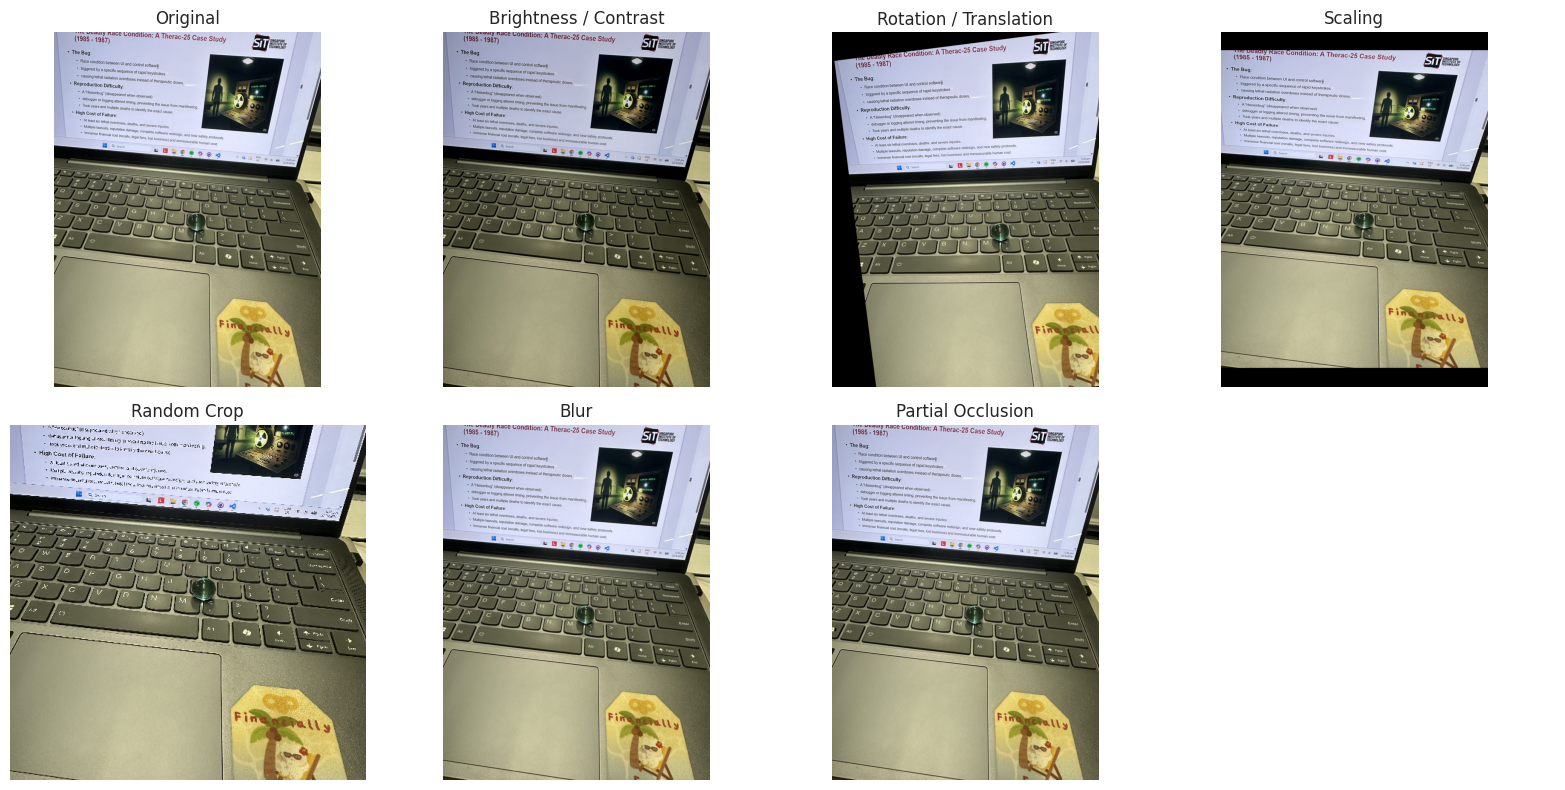

In [ ]:
# Preview augmentation effects on one training image
sample_image = cv2.imread(str(image_files["Marbles"][0]))
sample_image = cv2.cvtColor(sample_image, cv2.COLOR_BGR2RGB)

augmentations = {
    "Original": None,
    "Brightness / Contrast": A.RandomBrightnessContrast(p=1),
    "Rotation / Translation": A.Affine(rotate=(-10, 10), translate_percent=(-0.1, 0.1), p=1),
    "Scaling": A.Affine(scale=(0.8, 1.2), p=1),
    "Random Crop": A.RandomResizedCrop(size=(480, 480), scale=(0.7, 1.0), p=1),
    "Blur": A.GaussianBlur(blur_limit=(3, 5), p=1),
    "Partial Occlusion": A.CoarseDropout(
        num_holes_range=(1, 3),
        hole_height_range=(10, 40),
        hole_width_range=(10, 40),
        p=1
    ),
}

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, (name, transform) in zip(axes.flat, augmentations.items()):
    image = sample_image if transform is None else transform(image=sample_image)["image"]

    ax.imshow(image)
    ax.set_title(name)
    ax.axis("off")

for ax in axes.flat[len(augmentations):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# YOLOv8 augmentation parameters for training
yolo_augmentation = {
    "hsv_h": 0.015,
    "hsv_s": 0.5,
    "hsv_v": 0.4,
    "degrees": 10.0,
    "translate": 0.1,
    "scale": 0.3,
    "fliplr": 0.5,
}

# Reuse in Section 6:
# model.train(data=str(DATA_YAML), epochs=50, **yolo_augmentation)

## 6. YOLOv8 Object Detection Model Training

A pretrained **YOLOv8 Nano (YOLOv8n)** model will be fine-tuned using the prepared hazardous-object dataset.

Transfer learning allows the model to reuse previously learned visual features while adapting to the project's specific object classes.

The training process includes:

- **Dataset Configuration:** Load the prepared training and validation datasets, together with the predefined class labels from `data.yaml`.
- **Model Initialisation:** Load the pretrained YOLOv8n weights (`yolov8n.pt`).
- **Model Training:** Train the model for up to 50 epochs using an image size of 640 × 640 and a batch size of 8.
- **Data Augmentation:** Apply the configured augmentation techniques during training to improve model robustness and generalisation.
- **Performance Monitoring:** Monitor training and validation performance, with early stopping to reduce unnecessary training.
- **Model Saving:** Save the best-performing model weights (`best.pt`) and back them up to Google Drive.

The trained model will be used to detect and classify hazardous household objects, generating bounding boxes and confidence scores for each detection. These outputs will subsequently support the child-safety monitoring and alert system.

In [ ]:
# Load and verify dataset configuration
DATA_YAML = Path("/content/child_safety_dataset/data.yaml")

if not DATA_YAML.is_file():
    raise FileNotFoundError("Complete Section 4 before training.")

with open(DATA_YAML, "r") as file:
    dataset_config = yaml.safe_load(file)

# Define shared training settings
DEVICE = 0
EPOCHS = 30
IMAGE_SIZE = 640
BATCH_SIZE = 8

# Verify GPU availability
if not torch.cuda.is_available():
    raise RuntimeError("GPU not detected. Enable GPU in Colab runtime settings.")

# Display training configuration
print("Dataset loaded:", DATA_YAML)
print("Number of classes:", len(dataset_config["names"]))
print("GPU:", torch.cuda.get_device_name(DEVICE))
print("Epochs:", EPOCHS)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)

Dataset loaded: /content/child_safety_dataset/data.yaml
Number of classes: 15
GPU: Tesla T4
Epochs: 30
Image size: 640
Batch size: 8


### 6.1 Baseline Model

A pretrained YOLOv8n model is fine-tuned using the prepared hazardous-object dataset to establish baseline detection performance.

The baseline serves as a reference for evaluating the effectiveness of subsequent hyperparameter adjustments.

#### 6.1.1 Model Training

The baseline model is trained using the predefined training configuration and data augmentation settings.

An initial learning rate of 0.001 and the AdamW optimizer are used. Training is performed for a maximum of 30 epochs, with early stopping based on validation performance.

In [ ]:
# Initialise pretrained YOLOv8n model
baseline_model = YOLO("yolov8n.pt")

# Train baseline model
baseline_model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    optimizer="AdamW",
    lr0=0.001,
    patience=10,
    seed=SEED,
    device=DEVICE,
    project="/content/runs/child_safety",
    name="baseline",
    plots=True,
    **yolo_augmentation
)

# Store baseline training results
BASELINE_DIR = Path(baseline_model.trainer.save_dir)
BASELINE_BEST = Path(baseline_model.trainer.best)

print("Baseline training completed!")
print("Results:", BASELINE_DIR)
print("Best model:", BASELINE_BEST)

Ultralytics 8.4.185 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/child_safety_dataset/data.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline, nbs=64, nms=None, opset=None, optimize

#### 6.1.2 Results

The baseline model is evaluated using the validation dataset.

Performance is measured using precision, recall, mAP@50, and mAP@50–95. Training curves are also visualised to examine the behaviour of the model throughout training.

Ultralytics 8.4.185 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,136,109 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2308.4±1151.4 MB/s, size: 132.8 KB)
val: Scanning /content/child_safety_dataset/labels/val.cache... 1751 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1751/1751 408.0Mit/s 0.0s
val: /content/child_safety_dataset/images/val/Pill_bottle__pill_bottle_ (40)__jpg.jpg: corrupt JPEG restored and saved
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 219/219 9.7it/s 22.7s
                   all       1751       2629      0.739      0.711      0.748      0.553
               battery         68        161      0.916      0.813      0.892      0.669
             bottlecap        410        719      0.969      0.975       0.98      0.831
                  coin         99        264      0.804      0.845      0.874      0.74

,Model,Precision,Recall,mAP50,mAP50-95
0,Baseline,0.739449,0.711493,0.74759,0.552597


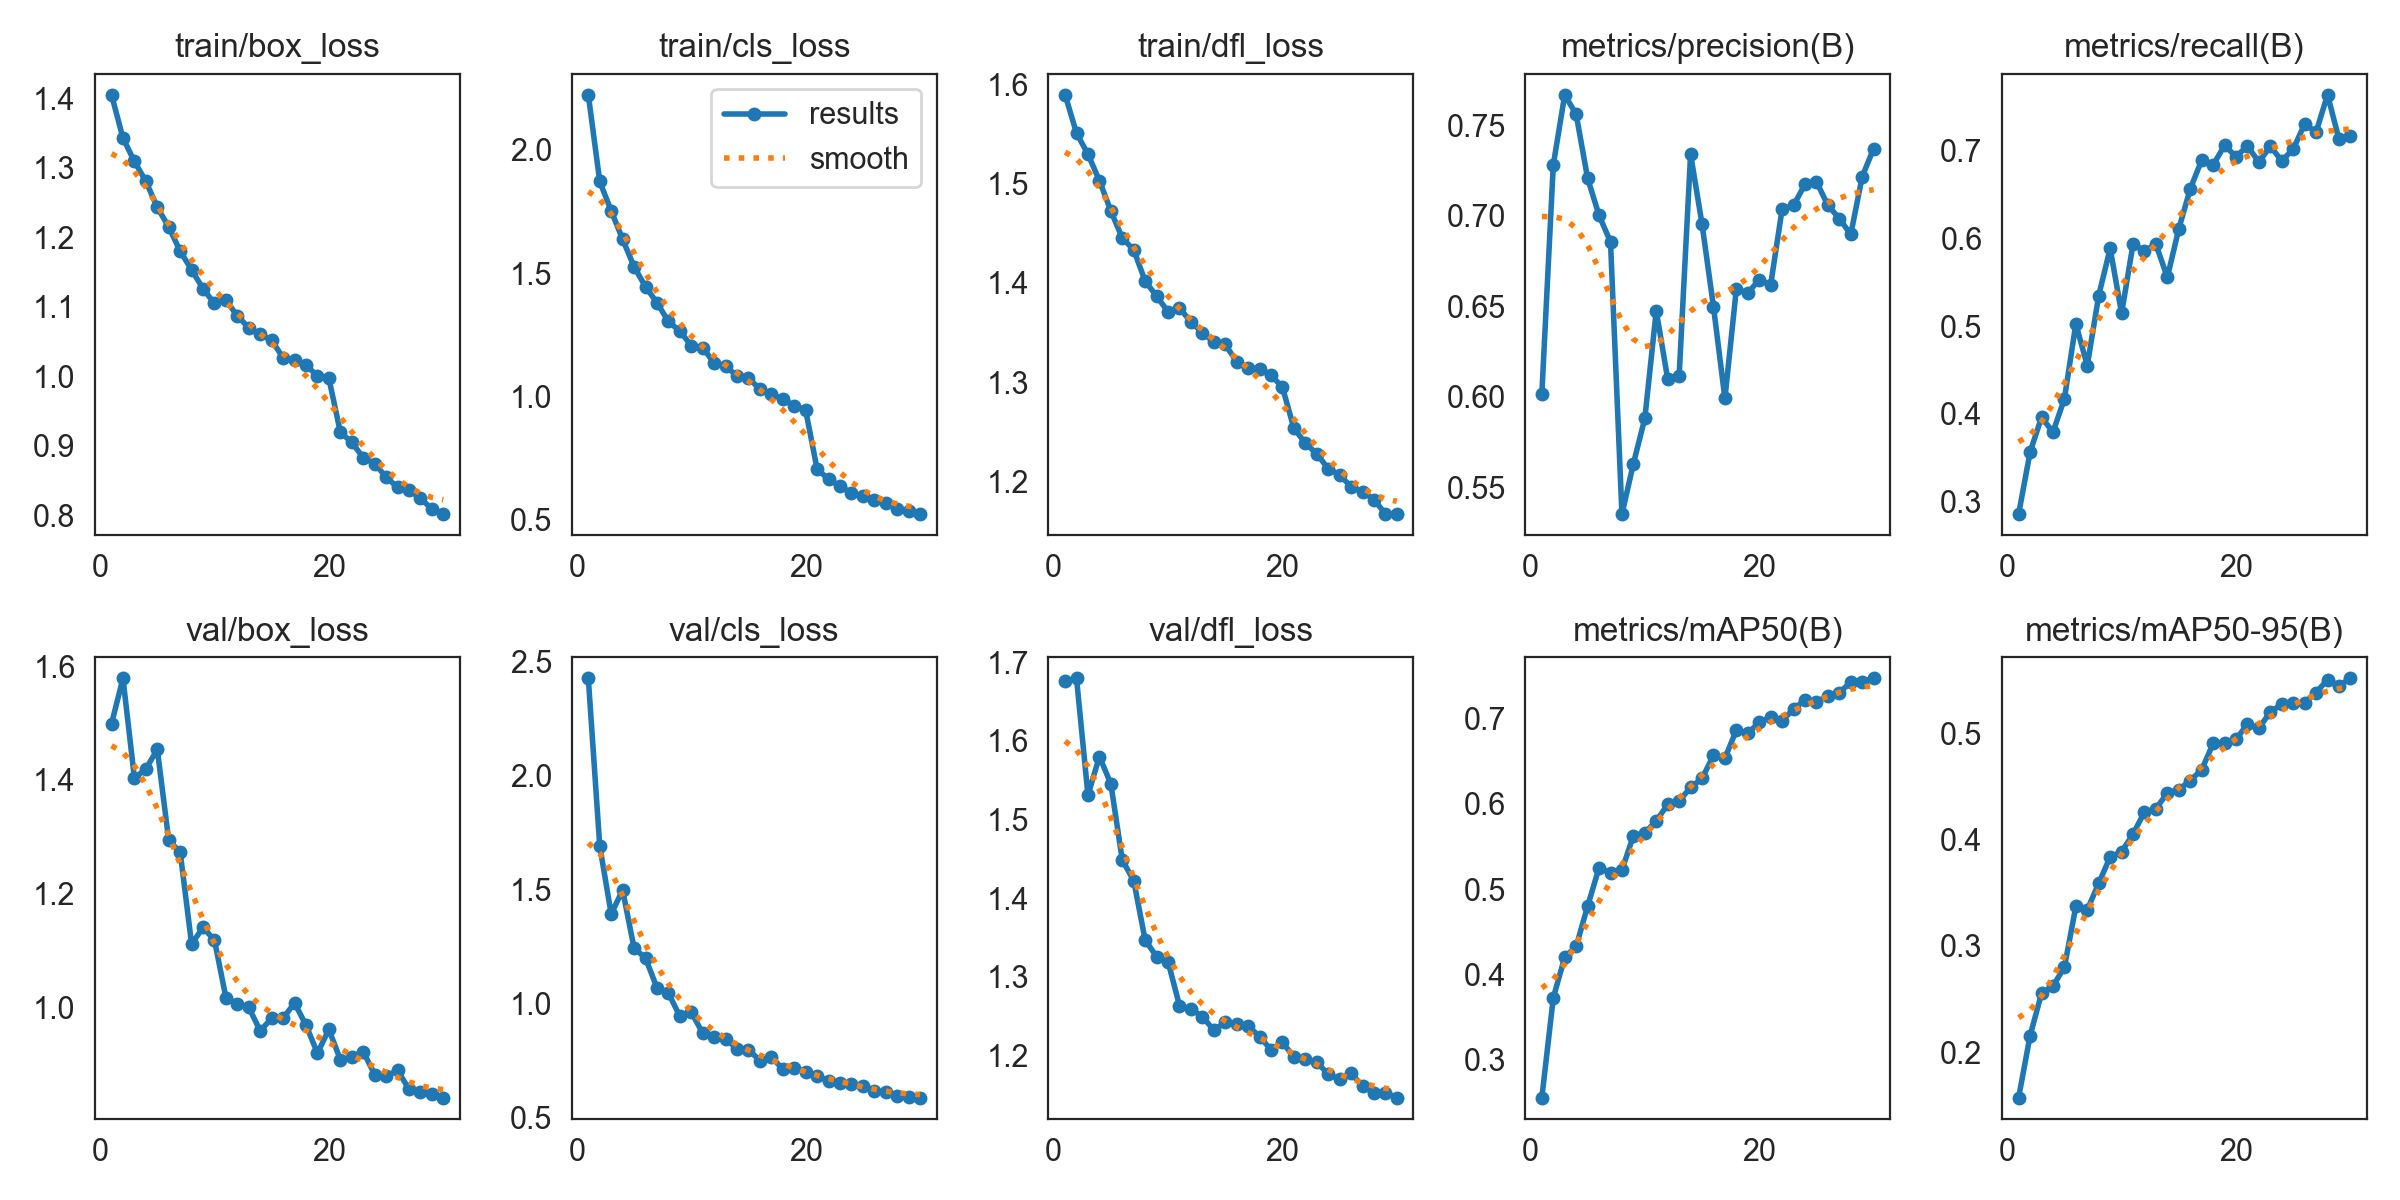

In [ ]:
# Evaluate best baseline model on validation dataset
baseline_metrics = YOLO(str(BASELINE_BEST)).val(
    data=str(DATA_YAML),
    split="val",
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    plots=True
)

# Display baseline evaluation metrics
baseline_results = pd.DataFrame([{
    "Model": "Baseline",
    "Precision": baseline_metrics.box.mp,
    "Recall": baseline_metrics.box.mr,
    "mAP50": baseline_metrics.box.map50,
    "mAP50-95": baseline_metrics.box.map
}])

display(baseline_results)

# Visualise training curves
display(IPImage(filename=str(BASELINE_DIR / "results.png")))

#### 6.1.3 Analysis

The baseline results are analysed to assess detection accuracy, model convergence, and generalisation performance.

The analysis focuses on:

- **Detection Performance:** Evaluate precision, recall, and mAP to determine the model's ability to identify hazardous objects.
- **Training Behaviour:** Examine training and validation loss curves for evidence of convergence, overfitting, or underfitting.
- **Class-Level Performance:** Identify object classes with lower detection performance, particularly small hazardous objects.
- **Areas for Improvement:** Determine which hyperparameters should be investigated in the next experiment.

The findings will be documented after baseline training and evaluation are completed.

#### 6.1.4 Model Saving

The best-performing baseline checkpoint is saved to Google Drive to preserve the trained model for subsequent comparison and evaluation.

In [ ]:
# Define Google Drive folder for saving trained models
SAVE_DIR = Path("/content/drive/MyDrive/Colab Notebooks/CVDL Model")

# Create folder automatically if it does not exist
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# Save baseline model weights
shutil.copy2(BASELINE_BEST, SAVE_DIR / "baseline_best.pt")

# Save baseline evaluation results
baseline_results.to_csv(SAVE_DIR / "baseline_results.csv", index=False)

print("Baseline model and results saved to:", SAVE_DIR)

Baseline model and results saved to: /content/drive/MyDrive/Colab Notebooks/CVDL Model


### 6.2 Hyperparameter Tuning — Experiment 1: Learning Rate

The first experiment investigates the effect of reducing the initial learning rate from 0.001 to 0.0005.

A lower learning rate allows smaller adjustments to the model weights during training, potentially improving convergence and model generalisation.

All remaining training parameters are kept consistent with the baseline to ensure a fair comparison.

#### 6.2.1 Model Training

A new pretrained YOLOv8n model is fine-tuned using a reduced learning rate of 0.0005.

The dataset split, optimizer, image resolution, batch size, maximum epochs, and data augmentation settings remain unchanged from the baseline.

In [ ]:
# Initialise pretrained YOLOv8n model
experiment1_model = YOLO("yolov8n.pt")

# Train model with reduced learning rate
experiment1_model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    optimizer="AdamW",
    lr0=0.0005,
    patience=10,
    seed=SEED,
    device=DEVICE,
    project="/content/runs/child_safety",
    name="experiment1_learning_rate",
    plots=True,
    **yolo_augmentation
)

# Store experiment training results
EXP1_DIR = Path(experiment1_model.trainer.save_dir)
EXP1_BEST = Path(experiment1_model.trainer.best)

print("Experiment 1 training completed!")
print("Results:", EXP1_DIR)
print("Best model:", EXP1_BEST)

Ultralytics 8.4.185 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/child_safety_dataset/data.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=experiment1_learning_rate, nbs=64, nms=None, op

#### 6.2.2 Results

The tuned model is evaluated using the same validation dataset and performance metrics as the baseline.

Precision, recall, mAP@50, and mAP@50–95 are recorded. Training curves are visualised to assess whether reducing the learning rate improves model convergence and detection performance.

Ultralytics 8.4.185 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,136,109 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2305.1±1066.2 MB/s, size: 132.8 KB)
val: Scanning /content/child_safety_dataset/labels/val.cache... 1751 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1751/1751 386.5Mit/s 0.0s
val: /content/child_safety_dataset/images/val/Pill_bottle__pill_bottle_ (40)__jpg.jpg: corrupt JPEG restored and saved
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 219/219 9.7it/s 22.5s
                   all       1751       2629      0.762      0.786      0.798      0.598
               battery         68        161      0.889      0.832      0.888      0.691
             bottlecap        410        719      0.964      0.981      0.981      0.852
                  coin         99        264      0.851      0.867      0.907      0.75

,Model,Precision,Recall,mAP50,mAP50-95
0,Baseline,0.739449,0.711493,0.747590,0.552597
1,Experiment 1,0.761670,0.786199,0.798084,0.598347


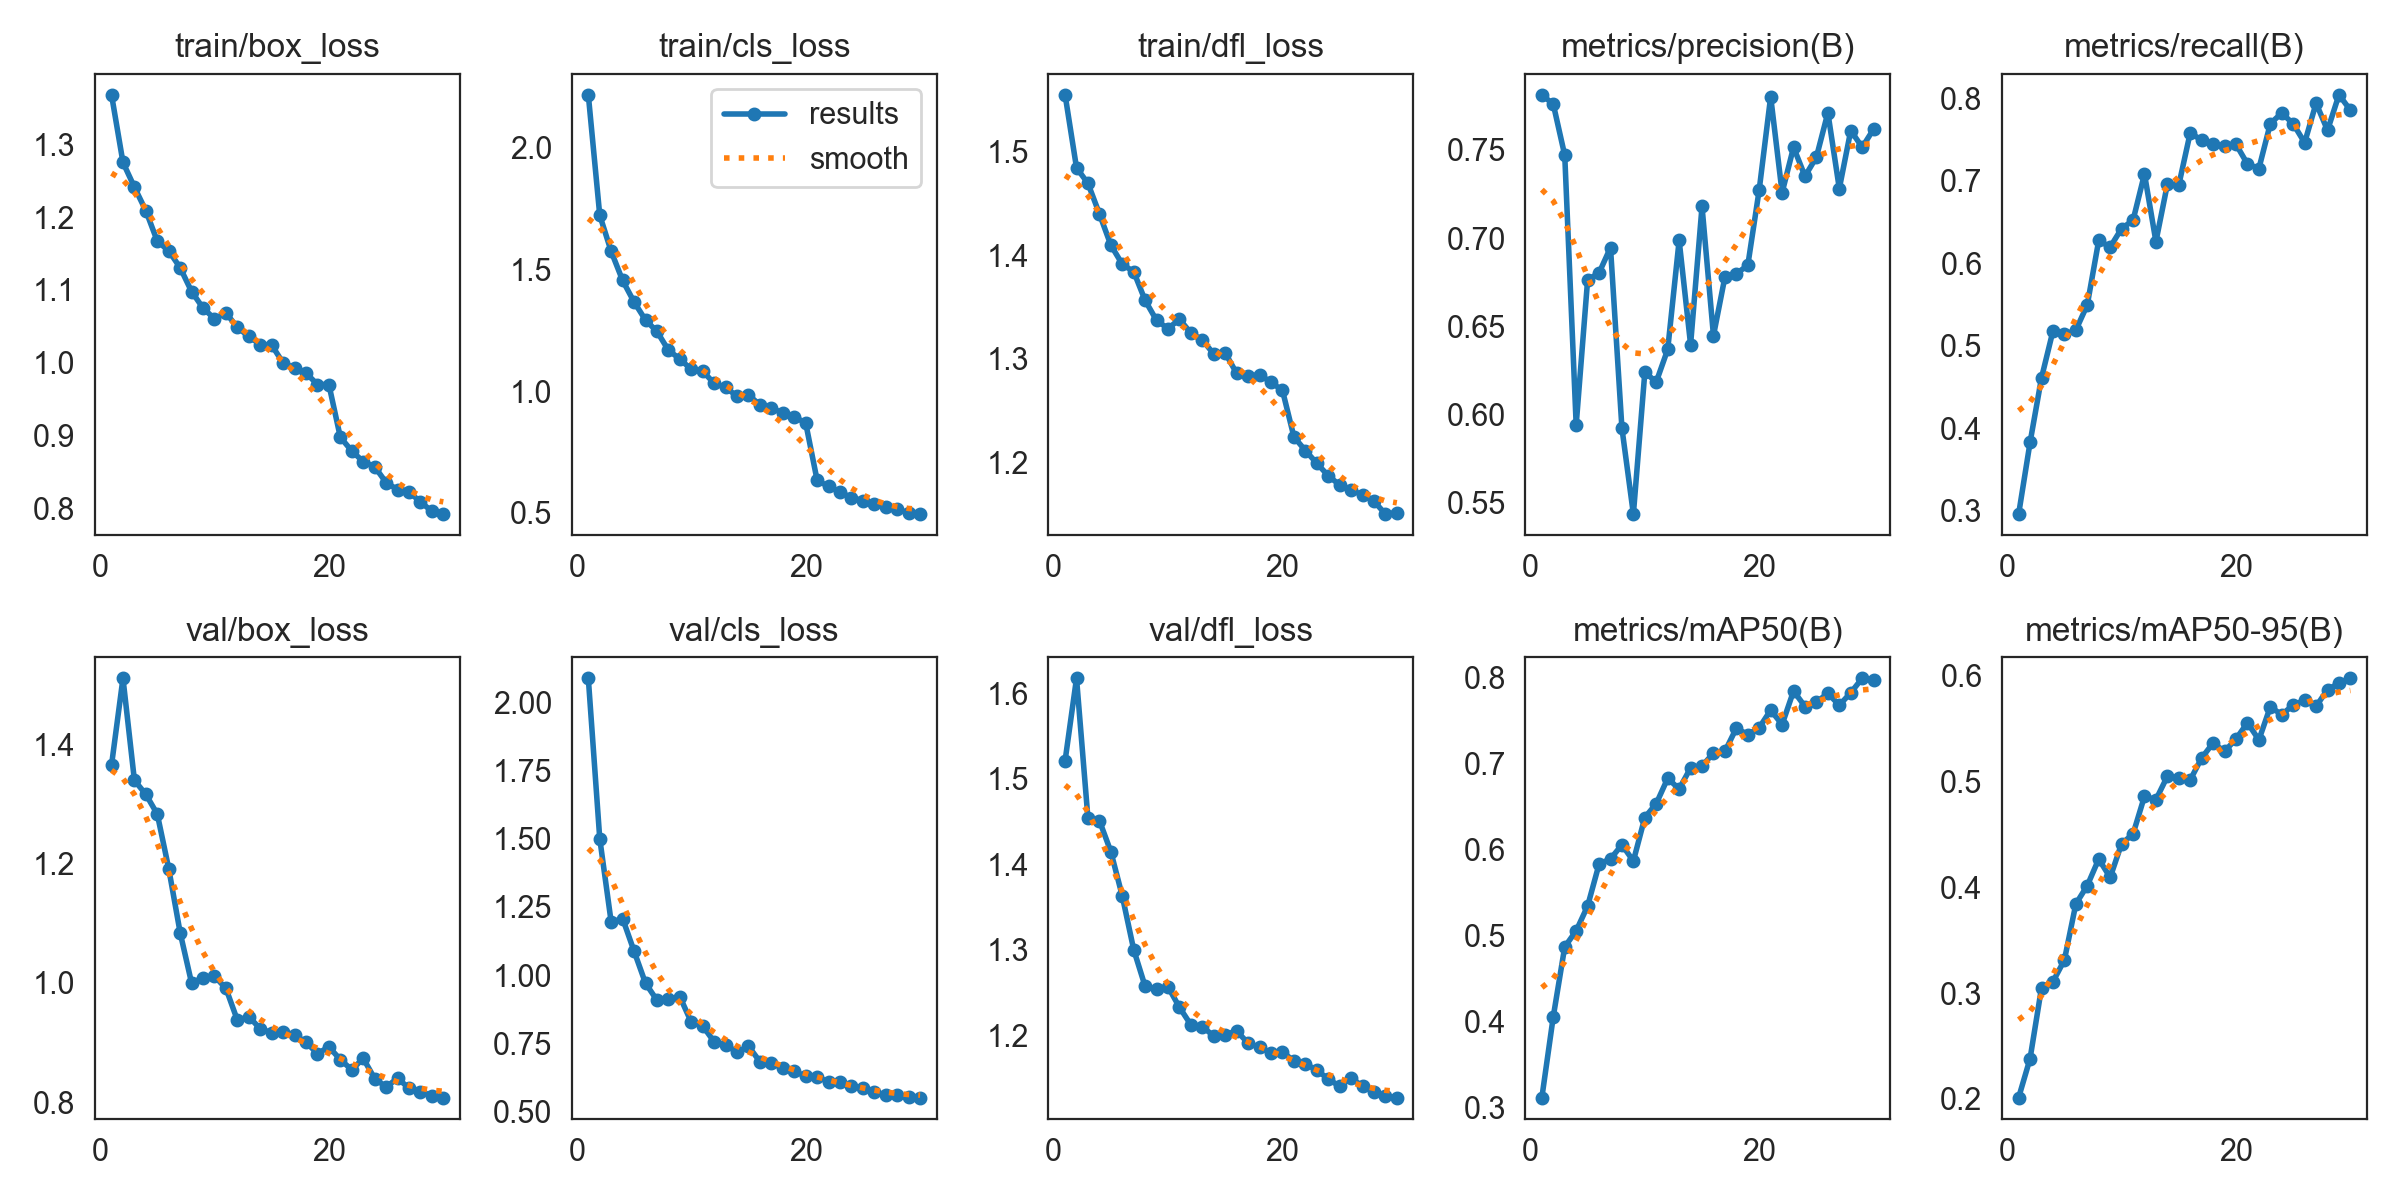

In [ ]:
# Evaluate Experiment 1 using validation dataset
experiment1_metrics = YOLO(str(EXP1_BEST)).val(
    data=str(DATA_YAML),
    split="val",
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    plots=True
)

# Store evaluation metrics
experiment1_results = pd.DataFrame([{
    "Model": "Experiment 1",
    "Precision": experiment1_metrics.box.mp,
    "Recall": experiment1_metrics.box.mr,
    "mAP50": experiment1_metrics.box.map50,
    "mAP50-95": experiment1_metrics.box.map
}])

# Compare experiment against baseline
display(pd.concat([baseline_results, experiment1_results], ignore_index=True))

# Display training curves
from IPython.display import Image as IPImage, display
display(IPImage(filename=str(EXP1_DIR / "results.png")))

#### 6.2.3 Analysis

The performance of Experiment 1 is compared against the baseline model to determine the effect of reducing the learning rate.

The analysis considers:

- **Detection Performance:** Changes in precision, recall, mAP@50, and mAP@50–95.
- **Training Convergence:** Differences in the training and validation loss curves.
- **Generalisation:** Whether the adjusted learning rate improves validation performance.
- **Experimental Outcome:** Whether the tuned configuration provides a measurable improvement over the baseline.

The findings will be documented after examining the experimental results.

#### 6.2.4 Model Saving

The best-performing checkpoint from Experiment 1 and its validation metrics are saved to Google Drive for subsequent model comparison.

In [ ]:
# Save Experiment 1 model and results
SAVE_DIR.mkdir(parents=True, exist_ok=True)

shutil.copy2(EXP1_BEST, SAVE_DIR / "experiment1_best.pt")
experiment1_results.to_csv(
    SAVE_DIR / "experiment1_results.csv", index=False
)

print("Experiment 1 model and results saved to:", SAVE_DIR)

Experiment 1 model and results saved to: /content/drive/MyDrive/Colab Notebooks/CVDL Model


### 6.3 Hyperparameter Tuning — Experiment 2: Image Resolution

The second experiment investigates whether increasing the input image resolution from 640 × 640 to 800 × 800 improves hazardous-object detection performance.

A higher resolution may preserve more visual details of small objects, potentially improving their detection. However, it also increases computational requirements.

The learning rate and other training parameters are restored to their baseline values to isolate the effect of image resolution.

#### 6.3.1 Model Training

A new pretrained YOLOv8n model is fine-tuned using an increased input resolution of 800 × 800.

The initial learning rate of 0.001, AdamW optimizer, batch size, maximum epochs, and augmentation settings remain consistent with the baseline.

In [ ]:
# Define increased image resolution
EXP2_IMAGE_SIZE = 800

# Initialise pretrained YOLOv8n model
experiment2_model = YOLO("yolov8n.pt")

# Train model with increased image resolution
experiment2_model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=EXP2_IMAGE_SIZE,
    batch=BATCH_SIZE,
    optimizer="AdamW",
    lr0=0.001,
    patience=10,
    seed=SEED,
    device=DEVICE,
    project="/content/runs/child_safety",
    name="experiment2_image_resolution",
    plots=True,
    **yolo_augmentation
)

# Store experiment training results
EXP2_DIR = Path(experiment2_model.trainer.save_dir)
EXP2_BEST = Path(experiment2_model.trainer.best)

print("Experiment 2 training completed!")
print("Results:", EXP2_DIR)
print("Best model:", EXP2_BEST)

Ultralytics 8.4.185 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/child_safety_dataset/data.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=800, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=experiment2_image_resolution, nbs=64, nms=None, 

#### 6.3.2 Results

The model is evaluated on the validation dataset to determine whether the increased image resolution improves detection performance.

Precision, recall, mAP@50, and mAP@50–95 are recorded and compared with the baseline and previous experiment.

Training curves are examined to assess model convergence.

Ultralytics 8.4.185 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,136,109 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2118.9±1336.5 MB/s, size: 132.8 KB)
val: Scanning /content/child_safety_dataset/labels/val.cache... 1751 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1751/1751 408.0Mit/s 0.0s
val: /content/child_safety_dataset/images/val/Pill_bottle__pill_bottle_ (40)__jpg.jpg: corrupt JPEG restored and saved
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 219/219 7.6it/s 28.7s
                   all       1751       2629      0.676      0.765      0.735      0.536
               battery         68        161      0.912      0.837      0.887      0.627
             bottlecap        410        719       0.96      0.974       0.98      0.834
                  coin         99        264      0.824      0.867      0.893      0.73

,Model,Precision,Recall,mAP50,mAP50-95
0,Baseline,0.739449,0.711493,0.747590,0.552597
1,Experiment 1,0.761670,0.786199,0.798084,0.598347
2,Experiment 2,0.675870,0.765245,0.735205,0.535829


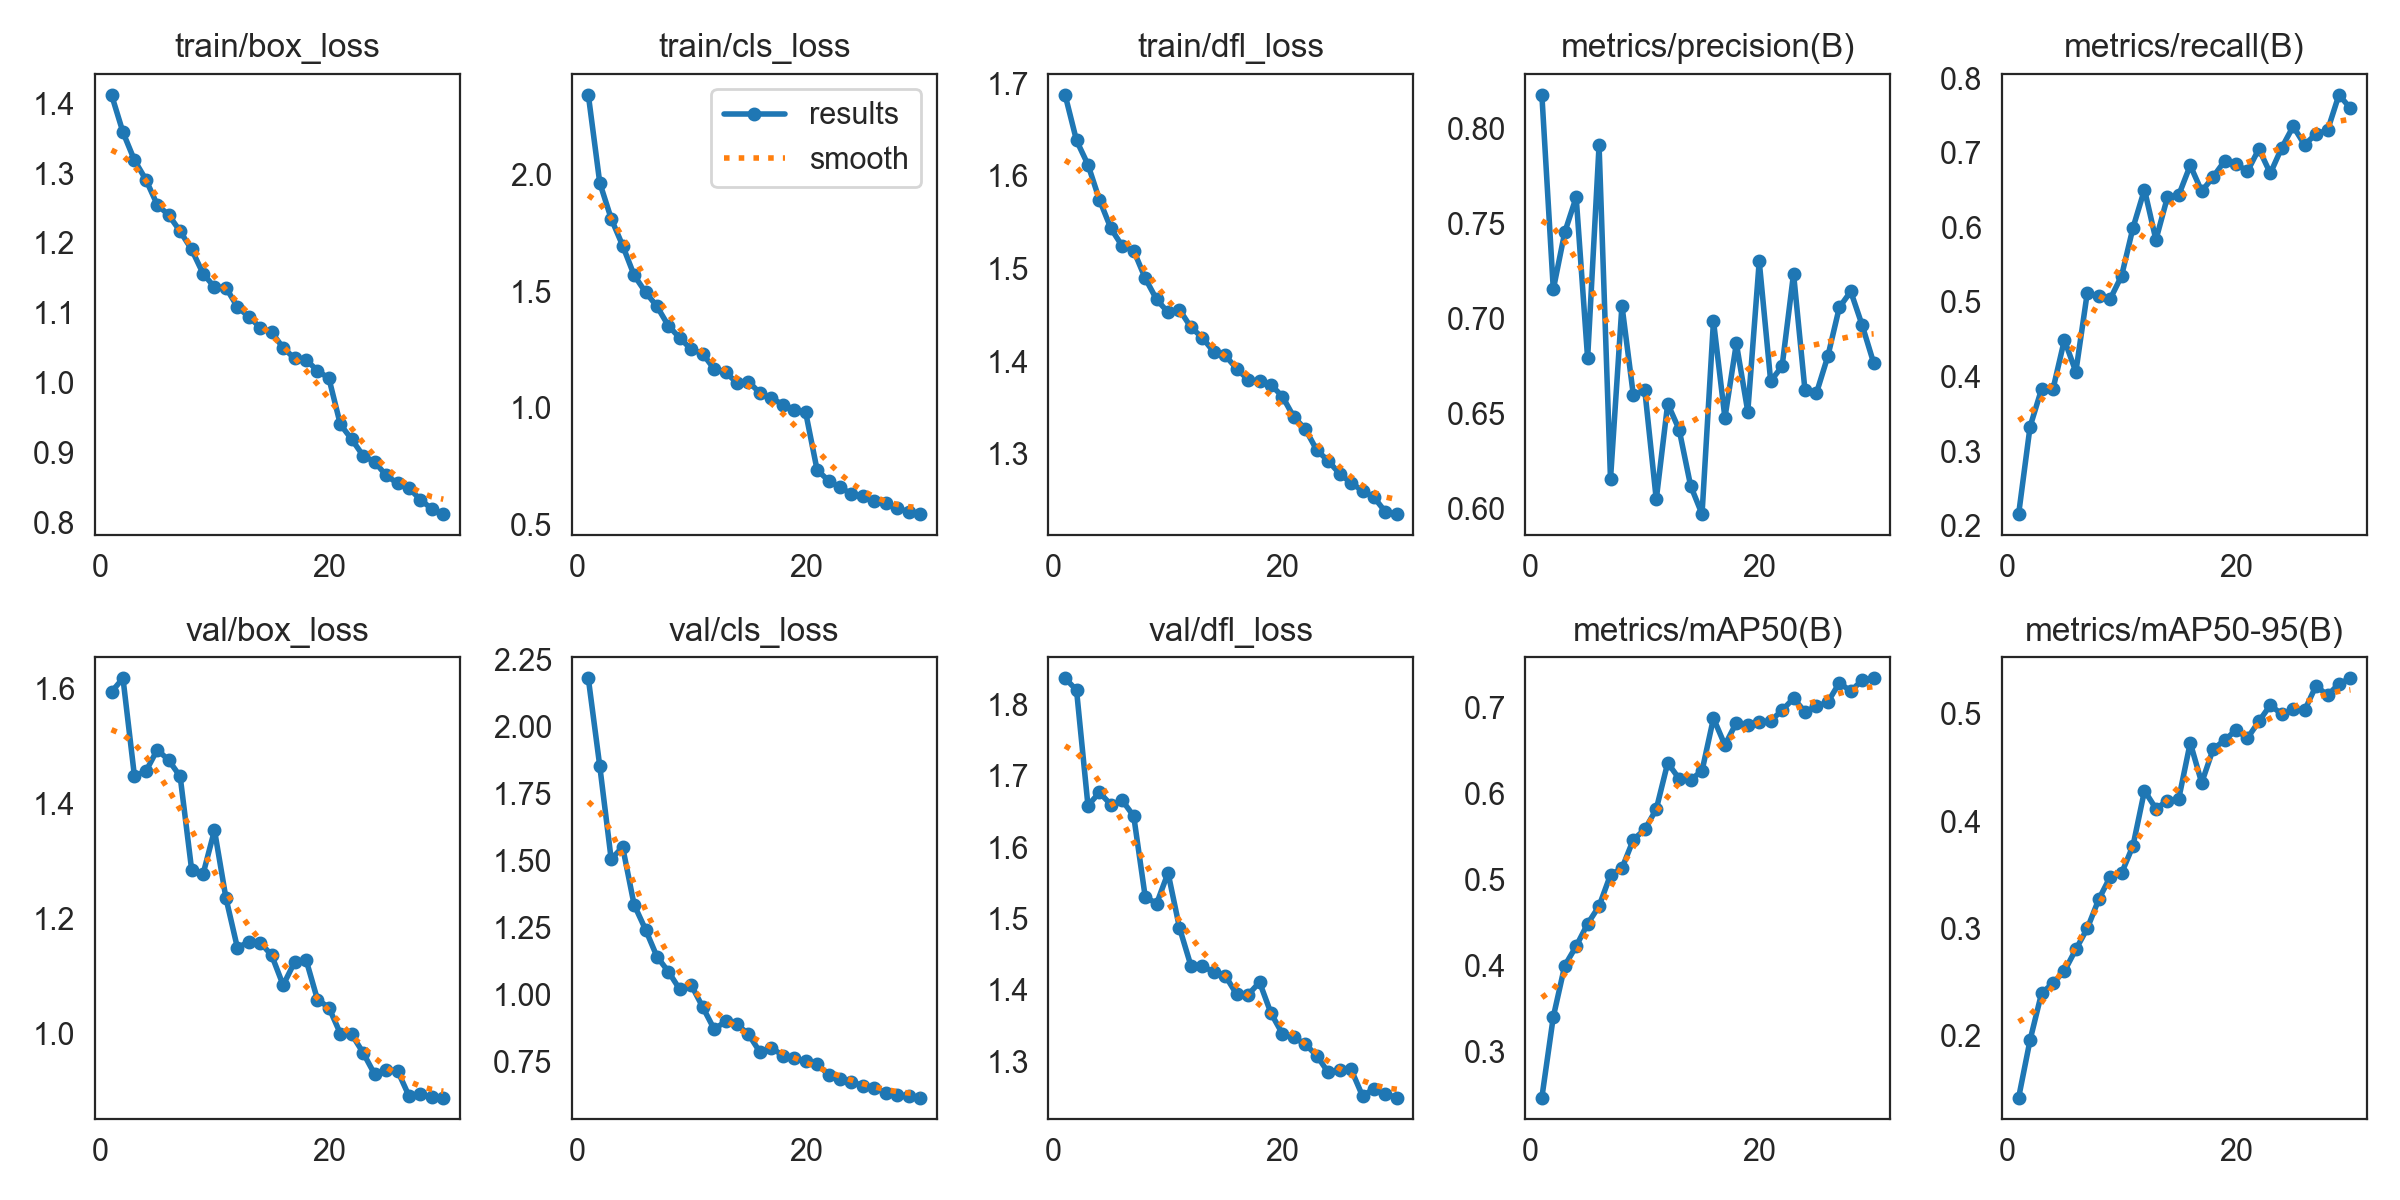

In [ ]:
# Evaluate Experiment 2 using validation dataset
experiment2_metrics = YOLO(str(EXP2_BEST)).val(
    data=str(DATA_YAML),
    split="val",
    imgsz=EXP2_IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    plots=True
)

# Store evaluation metrics
experiment2_results = pd.DataFrame([{
    "Model": "Experiment 2",
    "Precision": experiment2_metrics.box.mp,
    "Recall": experiment2_metrics.box.mr,
    "mAP50": experiment2_metrics.box.map50,
    "mAP50-95": experiment2_metrics.box.map
}])

# Compare available model results
display(pd.concat([
    baseline_results,
    experiment1_results,
    experiment2_results
], ignore_index=True))

# Display training curves
display(IPImage(filename=str(EXP2_DIR / "results.png")))

#### 6.3.3 Analysis

Experiment 2 is analysed to determine whether increasing input image resolution improves object detection performance.

The analysis focuses on:

- **Detection Performance:** Changes in precision, recall, and mAP compared with the baseline.
- **Small-Object Detection:** Whether small hazardous objects are detected more reliably.
- **Training Behaviour:** Changes in convergence and validation performance.
- **Computational Requirements:** The impact of higher resolution on training speed and GPU memory usage.
- **Experimental Outcome:** Whether the performance improvement justifies the additional computational cost.

The findings will be documented after examining the experimental results.

#### 6.3.4 Model Saving

The best-performing checkpoint from Experiment 2 and its validation metrics are saved to Google Drive for comparison with previously trained models.

In [ ]:
# Save Experiment 2 model and results
SAVE_DIR.mkdir(parents=True, exist_ok=True)

shutil.copy2(EXP2_BEST, SAVE_DIR / "experiment2_best.pt")
experiment2_results.to_csv(
    SAVE_DIR / "experiment2_results.csv", index=False
)

print("Experiment 2 model and results saved to:", SAVE_DIR)

Experiment 2 model and results saved to: /content/drive/MyDrive/Colab Notebooks/CVDL Model


### 6.4 Model Comparison and Selection

The baseline and hyperparameter-tuned models are compared using their validation performance.

The model with the highest mAP@50–95 is selected as the final model. Its trained weights are saved as `final_best.pt` for independent test evaluation in Section 7.

In [ ]:
# Define saved experiment files
SAVE_DIR = Path("/content/drive/MyDrive/Colab Notebooks/CVDL Model")

experiments = {
    "Baseline": "baseline",
    "Experiment 1": "experiment1",
    "Experiment 2": "experiment2"
}

# Load results from completed experiments
comparison = []

for name, prefix in experiments.items():
    model_path = SAVE_DIR / f"{prefix}_best.pt"
    results_path = SAVE_DIR / f"{prefix}_results.csv"

    if model_path.is_file() and results_path.is_file():
        metrics = pd.read_csv(results_path).iloc[0]

        comparison.append({
            "Model": name,
            "Precision": metrics["Precision"],
            "Recall": metrics["Recall"],
            "mAP50": metrics["mAP50"],
            "mAP50-95": metrics["mAP50-95"],
            "Path": model_path
        })

if not comparison:
    raise FileNotFoundError("No saved experiment results found.")

# Compare models using validation performance
df_comparison = pd.DataFrame(comparison)
display(df_comparison.drop(columns="Path"))

# Select model with highest validation mAP50-95
best = df_comparison.loc[df_comparison["mAP50-95"].idxmax()]

# Save selected model for final evaluation
FINAL_MODEL_PATH = SAVE_DIR / "final_best.pt"
shutil.copy2(best["Path"], FINAL_MODEL_PATH)

print("Selected model:", best["Model"])
print("Best validation mAP50-95:", round(best["mAP50-95"], 4))
print("Final model saved:", FINAL_MODEL_PATH)

## 7. Final Model Evaluation

The best-performing YOLOv8 model selected from the baseline and hyperparameter tuning experiments will be evaluated using the independent **test dataset (15%)**.

Unlike the validation dataset used during model development, the test dataset remains unseen during training and hyperparameter selection. This provides an unbiased assessment of the final model's generalisation performance.

The main evaluation metrics include:

- **Precision:** The proportion of predicted detections that are correct.
- **Recall:** The proportion of actual hazardous objects successfully detected.
- **mAP@50:** Mean Average Precision using an IoU threshold of 0.50.
- **mAP@50–95:** Mean Average Precision averaged across IoU thresholds from 0.50 to 0.95.

Qualitative evaluation will also be performed by visualising predicted bounding boxes and examining missed detections, incorrect classifications, and false positives.

Particular attention will be given to small hazardous objects, as missed detections may affect the reliability of the child-safety monitoring system.

### 7.1 Final Model Loading

The best-performing YOLOv8 model selected from the baseline and hyperparameter tuning experiments is loaded for final evaluation.

The selected model is evaluated using the independent test dataset, which has not been used for model training or hyperparameter selection.

In [ ]:
# Define selected final model path
SAVE_DIR = Path("/content/drive/MyDrive/Colab Notebooks/CVDL Model")
FINAL_MODEL_PATH = SAVE_DIR / "final_best.pt"

# Verify final model exists
if not FINAL_MODEL_PATH.is_file():
    raise FileNotFoundError("Select and save the final model in Section 6.4 first.")

# Load final trained YOLOv8 model
final_model = YOLO(str(FINAL_MODEL_PATH))

# Reuse the selected model's training image size
TEST_IMAGE_SIZE = int(final_model.overrides.get("imgsz", IMAGE_SIZE))

print("Final model loaded:", FINAL_MODEL_PATH)
print("Evaluation image size:", TEST_IMAGE_SIZE)

FileNotFoundError: Select and save the final model in Section 6.4 first.

### 7.2 Quantitative Model Evaluation

The final model is evaluated on the held-out test dataset to measure its ability to detect and classify hazardous objects.

Overall precision, recall, mAP@50, and mAP@50–95 are calculated to assess detection performance.

Class-level results are also examined to identify hazardous objects that are detected less reliably. A confusion matrix and precision-recall curves are generated to support further analysis.

In [ ]:
# Define final evaluation output directory
TEST_DIR = SAVE_DIR / "final_test"
TEST_DIR.mkdir(parents=True, exist_ok=True)

# Evaluate final model on unseen test dataset
test_metrics = final_model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=TEST_IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    plots=True,
    project=str(SAVE_DIR),
    name="final_test",
    exist_ok=True
)

# Store overall evaluation metrics
test_results = pd.DataFrame([{
    "Model": "Final YOLOv8n",
    "Precision": test_metrics.box.mp,
    "Recall": test_metrics.box.mr,
    "mAP50": test_metrics.box.map50,
    "mAP50-95": test_metrics.box.map
}])

print("Final Test Evaluation Results")
display(test_results)

# Store per-class evaluation metrics
class_results = pd.DataFrame([
    {
        "Class": CLASS_NAMES[int(cls)],
        "Precision": test_metrics.box.p[i],
        "Recall": test_metrics.box.r[i],
        "mAP50": test_metrics.box.ap50[i],
        "mAP50-95": test_metrics.box.ap[i]
    }
    for i, cls in enumerate(test_metrics.box.ap_class_index)
])

print("\nPer-Class Detection Performance")
display(class_results.sort_values("mAP50-95"))

# Save evaluation results to Google Drive
test_results.to_csv(TEST_DIR / "overall_metrics.csv", index=False)
class_results.to_csv(TEST_DIR / "class_metrics.csv", index=False)

### 7.3 Qualitative Model Evaluation

Qualitative evaluation is performed by visualising the final model's predictions on randomly selected test images.

Predicted bounding boxes, object labels, and confidence scores are examined to assess detection quality.

The evaluation focuses on identifying:

- **Correct Detections:** Hazardous objects accurately identified and localised.
- **Missed Detections:** Actual hazardous objects that the model fails to detect.
- **False Positives:** Incorrectly predicted hazardous objects.
- **Incorrect Classifications:** Objects detected but assigned to the wrong class.

Particular attention is given to small objects, overlapping objects, and visually challenging conditions.

In [ ]:
# Collect images from the test dataset
TEST_IMAGES = OUTPUT_PATH / "images" / "test"

test_images = sorted(
    file for file in TEST_IMAGES.iterdir()
    if file.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
)

# Randomly select test images for visual inspection
sample_images = random.Random(SEED).sample(
    test_images, min(6, len(test_images))
)

# Generate predictions and save annotated images
predictions = final_model.predict(
    source=[str(file) for file in sample_images],
    imgsz=TEST_IMAGE_SIZE,
    conf=0.25,
    device=DEVICE,
    save=True,
    project=str(TEST_DIR),
    name="sample_predictions",
    exist_ok=True
)

# Display predictions with bounding boxes
for prediction in predictions:
    annotated = cv2.cvtColor(
        prediction.plot(), cv2.COLOR_BGR2RGB
    )
    display(Image.fromarray(annotated))

print("Prediction images saved to:", TEST_DIR / "sample_predictions")

### 7.4 Final Performance Analysis

The final model's performance is analysed using the quantitative evaluation metrics and qualitative prediction results.

The analysis focuses on:

- **Overall Detection Performance:** Assess the final model using precision, recall, mAP@50, and mAP@50–95.
- **Class-Level Performance:** Identify hazardous-object categories with strong and weak detection performance.
- **Small-Object Detection:** Examine the model's ability to detect small hazards such as coins, batteries, and marbles.
- **Detection Errors:** Investigate missed detections, false positives, and incorrect classifications.
- **Model Generalisation:** Assess how well the selected model performs on previously unseen test images.
- **Limitations:** Discuss dataset imbalance, annotation quality, and challenging environmental conditions that may affect model reliability.

The findings will be documented based on the actual test results and prediction examples.